# Learning a catalyst activity field

In this example, we model a packed-bed reactor, a box filled with catalyst pellets through which a reacting fluid flows. We learn the catalyst activity, which varies through the bed, from noisy concentration measurements. A neural field represents the activity as a function of position ([function approximation](../overview/inference/function-approximation.md)), and we train it with AdamW, differentiating through every solve of the reactor model. This is Worked Example 2 of the diff-soup paper at a reduced size.

The training solves run in single precision (float32) on cuDSS, NVIDIA's sparse direct solver, so the notebook needs a GPU. The outputs come from an RTX 4070 Ti.

## Setup

We import diff-soup in JAX float64 (double-precision) mode ([enable float64](../installation/index.md#enable-float64)), which the data generation uses.

In [1]:
import time

import diff_soup as ds
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from diff_soup.domains import cartesian_grid_3d
from scipy.ndimage import gaussian_filter

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0].device_kind}")

diff-soup 1.1.0, JAX 0.11.2, NVIDIA GeForce RTX 4070 Ti


We keep every setting of the paper except the grid, which is coarser so that the run fits in the memory of this GPU. The right-hand comments give the paper's values.

In [2]:
# notebook run                         # paper
NX, NY = 64, 16                        # 96, 24    cells along and across the bed
STEPS = 1200                           # 1200      optimizer steps
WIDTH, DEPTH = 192, 3                  # 192, 3    hidden layers of the WIRE network
OMEGA_0, S_0 = 10.0, 5.0               # 10, 5     wavelet frequency and envelope
PEAK_LR, WEIGHT_DECAY = 1e-3, 1e-4     # 1e-3, 1e-4
CHECKPOINTS = 64                       # 64        checkpoints of the reverse pass

## The problem

We consider a bed of length $4W$ with a square cross-section of side $W$. Lengths are scaled by $W$, speeds by the mean superficial speed $U$ (the flow rate per unit cross-section), concentrations by the feed value $c_{\mathrm{in}}$ and time by $W/U$. The reactant concentration $c$ is advected by the flow, dispersed and consumed by the reaction,

$$
\frac{\partial c}{\partial t} + \frac{\partial}{\partial x}\big(u_x(y, z)\, c\big)
= D_{\mathrm{ax}} \frac{\partial^2 c}{\partial x^2}
+ D_{\mathrm{rad}} \Big(\frac{\partial^2 c}{\partial y^2} + \frac{\partial^2 c}{\partial z^2}\Big)
- k(\mathbf{x})\, \frac{c}{K + c},
$$

where $u_x(y, z)$ is a fixed velocity profile, $D_{\mathrm{ax}}$ and $D_{\mathrm{rad}}$ are the dispersion coefficients along and across the bed, $K$ is the saturation constant and $k(\mathbf{x})$ is the catalyst activity.

- The pellet diameter is $d_p = W/6$. The Péclet numbers are 2 along the bed and 10 across it, which gives $D_{\mathrm{ax}} = d_p/2$ and $D_{\mathrm{rad}} = d_p/10$.
- The reaction rate levels off at high concentration, following the Langmuir-Hinshelwood law with $K = 0.05$, and the mean activity $\bar k = 0.2223$ converts 80% of the feed in a fresh bed.

In [3]:
L, W = 4.0, 1.0                   # bed length and width
D_P = W / 6                       # pellet diameter
D_AX, D_RAD = D_P / 2, D_P / 10   # axial and radial dispersion
K, KBAR = 0.05, 0.2223            # saturation constant and mean activity
TS = np.linspace(1.0, 8.0, 8)     # measurement times
SIGMA = 0.01                      # noise standard deviation

- The feed enters through the Danckwerts condition $u_x c_{\mathrm{in}} = u_x c - D_{\mathrm{ax}} \partial c / \partial x$, which balances the incoming flow against dispersion at the inlet. It leaves with zero gradient, and the walls carry no flux.
- The bed starts empty, and the data are $c$ in every cell at $t = 1, \dots, 8$ with Gaussian noise of standard deviation $\sigma = 0.01$.

A neural field $N_\phi$ with weights $\phi$ represents the activity through a softplus, which keeps it positive and equal to $\bar k$ where the network outputs zero,

$$
k_\phi(\mathbf{x}) = \frac{\bar k}{\ln 2}\, \mathrm{softplus}\big(N_\phi(\mathbf{x})\big).
$$

We train it by minimizing the Gaussian negative log-likelihood over the measurement times $t_n$ and the cells $i$,

$$
\mathcal{L}(\phi) = \frac{1}{2\sigma^2} \sum_{n, i} \big(c_i(t_n;\, k_\phi) - c^{\mathrm{data}}_{n, i}\big)^2 .
$$

## Build the model

### Flow field

A packed bed is loosest next to its walls, so the flow channels along them. The velocity profile solves the Brinkman equation for viscous flow through a porous medium on the cross-section, with no slip at the walls,

$$
\mu_{\mathrm{eff}} \nabla^2 u_x - \frac{\mu}{\kappa(y, z)}\, u_x = \frac{\partial p}{\partial x},
$$

where $\mu_{\mathrm{eff}} / \mu = 8$ is the ratio of the effective to the fluid viscosity, $\partial p / \partial x$ is the driving pressure gradient and $\kappa = d_p^2 \varepsilon^3 / [150 (1 - \varepsilon)^2]$ is the Kozeny-Carman permeability of packed spheres. The porosity $\varepsilon$, the fraction of open space, rises from $\varepsilon_b = 0.4$ in the bulk towards one at the wall, $\varepsilon = \varepsilon_b + (1 - \varepsilon_b)\, e^{-5 \delta / d_p}$, with $\delta$ the distance to the wall.

Since this problem is linear and fixed, we solve it once with SciPy on a fine 192 × 192 cross-section and scale it to unit mean. Each cell of the reactor grid takes the block average of the fine profile, and we plot the profile on both grids across the middle of the bed.

In [4]:
N_REF = 192   # cells per side of the fine cross-section


def permeability(n):
    s = (np.arange(n) + 0.5) * W / n
    y, z = np.meshgrid(s, s, indexing="ij")
    delta = np.minimum(np.minimum(y, W - y), np.minimum(z, W - z))   # distance to the nearest wall
    eps = np.minimum(0.4 + 0.6 * np.exp(-5.0 * delta / D_P), 0.99)
    return D_P**2 * eps**3 / (150 * (1 - eps) ** 2)

In [5]:
def brinkman(n):
    h = W / n
    kappa = permeability(n)
    lap = sp.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(n, n)).tolil()
    lap[0, 0] = lap[-1, -1] = -3.0   # no slip: the ghost cell beyond the wall holds -u
    lap = sp.kron(lap, sp.identity(n)) + sp.kron(sp.identity(n), lap)
    A = 8.0 * lap.tocsc() / h**2 - sp.diags(1 / kappa.ravel())
    u = spla.spsolve(A.tocsc(), -np.ones(n * n)).reshape(n, n)
    return u / u.mean()

In [6]:
def block_average(a, n):
    b = a.shape[0] // n
    return a.reshape(n, b, n, b).mean(axis=(1, 3))


grid = cartesian_grid_3d(NX, NY, NY, L, W, W, method="fvm")
s_x, s_grid, _ = (np.asarray(s) for s in grid.coordinates)   # cell centres along and across the bed
u_ref = brinkman(N_REF)
u_yz = block_average(u_ref, NY)   # u_x on the reactor's cross-section
s_ref = (np.arange(N_REF) + 0.5) / N_REF
X, Y, Z = (np.asarray(a).reshape(-1) for a in grid.meshgrid())   # cell centres in field order
x_cells = np.stack([X, Y, Z], axis=1)
n_cells = x_cells.shape[0]

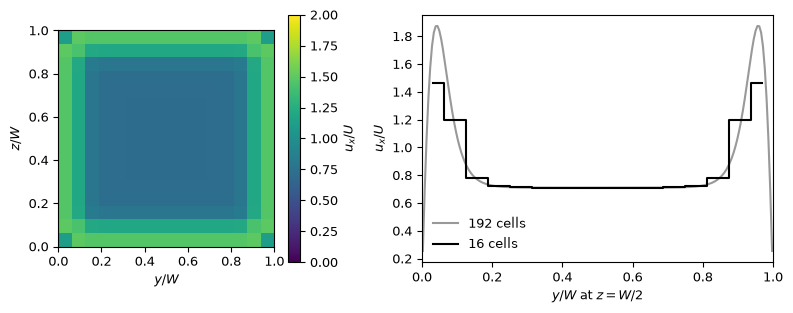

In [7]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(8, 3.2), width_ratios=[1, 1.3])
im = ax0.imshow(u_yz.T, origin="lower", extent=(0, W, 0, W), vmin=0, vmax=2)
fig.colorbar(im, ax=ax0, label="$u_x / U$")
ax0.set(xlabel="$y / W$", ylabel="$z / W$")
ax1.plot(s_ref, u_ref[:, N_REF // 2], color="0.6", label=f"{N_REF} cells")
ax1.step(s_grid, u_yz[:, NY // 2], where="mid", color="k", label=f"{NY} cells")
ax1.set(xlabel="$y / W$ at $z = W/2$", ylabel="$u_x / U$", xlim=(0, 1))
ax1.legend(frameon=False)
fig.tight_layout()

The fine profile peaks near twice the mean speed within one pellet diameter of each wall. On the 16-cell grid, this channel spreads over two or three cells and its peak flattens.

### Recipe

We declare the velocity as a fixed parameter with one value per cell and the activity as a learnable one ([learnable parameters](../overview/modeling/parameters.md)). The advection term uses `q.ops.div_advect`, the conservative form with central face fluxes as in the paper, and `q.ops.div_flux` takes one dispersion coefficient per axis ([operators](../overview/modeling/operators.md#operators-on-grids)). At the inlet, `spec.bc.inflow` imposes the Danckwerts condition ([boundary conditions](../overview/modeling/boundary-conditions.md)).

In [8]:
u_cells = np.broadcast_to(u_yz, (NX, NY, NY)).reshape(-1)


def build(precision):
    spec = ds.problem("packed_bed")
    spec.domain("bed", grid)
    spec.field("c", mass="differential", scale=1.0)
    spec.param("u_x", value=u_cells)
    k = spec.param("k", value=np.full(n_cells, KBAR), learnable=True)

    @spec.equation(writes="c", reads=("c",))
    def packed_bed(q):
        transport = -q.ops.div_advect(q.c, (q.p.u_x, 0.0, 0.0), scheme="central") + q.ops.div_flux((D_AX, D_RAD, D_RAD), q.c)
        return transport - q.p.k * q.c / (K + q.c)

    spec.bc.inflow("c", axis=0, side="low", velocity=u_yz.reshape(-1), value=1.0)
    return spec, spec.build(precision=precision), k

At the outlet the flow leaves at the value of the last cell, which is the zero-gradient condition. Next, we build the model twice, in float64 to generate the data and in end-to-end float32 to train ([precision](../overview/simulation/precision.md)), and `linear="auto"` picks cuDSS on a GPU. A solve receives the activity through `theta=`, which `ds.default_theta(problem, {k: values})` builds ([parameter gradients](../overview/simulation/sensitivities.md#parameter-gradients)).

In [9]:
spec, problem64, k64 = build(ds.Precision.fp64())
_, problem32, k32 = build(ds.Precision.fp32())
y0 = spec.assemble_state({"c": np.zeros(n_cells)})   # the bed starts empty
solver64 = ds.JNDF(rtol=1e-7, atol=1e-9, linear="auto")

First, we check the model on a fresh bed with the uniform activity $\bar k$, which should convert 80% of the feed at steady state.

In [10]:
theta = ds.default_theta(problem64, {k64: KBAR})   # a scalar fills every cell
fresh = ds.pdesolve(problem64, solver64, (0.0, 40.0), y0, theta=theta, saveat=ds.SaveAt(ts=[40.0]))
c_out = np.asarray(fresh.ys)[-1].reshape(NX, NY, NY)[-1]
print(f"conversion of the fresh bed: {1 - np.mean(u_yz * c_out):.3f}")

conversion of the fresh bed: 0.800


## True activity and synthetic data

The true activity is the mean activity multiplied by three factors, a random field, a poisoning front and a streak of inert pellets,

$$
k^*(\mathbf{x}) = \bar k\, e^{\psi(\mathbf{x})}\, f_{\mathrm{front}}(\mathbf{x})\, f_{\mathrm{streak}}(\mathbf{x}).
$$

The front and the streak switch on with the smooth step $s(\xi) = \tfrac12 [1 + \tanh(2.197\, \xi)]$, which rises from 10% to 90% over one unit of $\xi$.

In [11]:
def smoothstep(xi):
    return 0.5 * (1.0 + np.tanh(2.1972245773362196 * xi))

The random factor $\psi$ is a Gaussian random field with a correlation length of 0.25 and a standard deviation of 0.3. We draw it as a sum of 512 random Fourier features, so this realization differs from the paper's.

In [12]:
rng = np.random.default_rng(2026)
omega = rng.standard_normal((512, 3)) / 0.25
phase = rng.uniform(0.0, 2 * np.pi, 512)
psi = 0.3 * np.sqrt(2 / 512) * np.cos(x_cells @ omega.T + phase).sum(axis=1)

The poisoning front $f_{\mathrm{front}}$ drops the activity to 20% upstream of the breakthrough surface $x_f(y, z)$. Since the poison travels with the flow, $x_f$ follows the velocity profile averaged over one pellet diameter. The front sits 0.5 deeper in the wall channel than where the flow is slowest, around a mean position of 1.2.

In [13]:
u_pellet = block_average(gaussian_filter(u_ref, D_P * N_REF / W, mode="reflect"), NY)
u_pellet = u_pellet / u_pellet.mean()
x_f = 1.2 * (1 + 0.5 / (1.2 * np.ptp(u_pellet)) * (u_pellet - 1))   # (NY, NY)
front = 0.2 + 0.8 * smoothstep((X.reshape(NX, NY, NY) - x_f) / 0.4).reshape(-1)

Finally, the streak $f_{\mathrm{streak}}$ is a column of inert pellets of radius 0.15 around $(y, z) = (0.35, 0.62)$. It runs along the flow from $x = 2$ to $x = 3.5$ and holds 30% of the surrounding activity.

In [14]:
r = np.hypot(Y - 0.35, Z - 0.62)
streak = 1 - 0.7 * smoothstep((0.15 - r) / 0.08) * smoothstep((X - 2.0) / 0.2) * smoothstep((3.5 - X) / 0.2)
k_true = KBAR * np.exp(psi) * front * streak
print(f"k / kbar from {k_true.min() / KBAR:.2f} to {k_true.max() / KBAR:.2f}")

k / kbar from 0.10 to 2.37


Every plot of the bed shows the plane through the axis of the streak, with the flow from left to right.

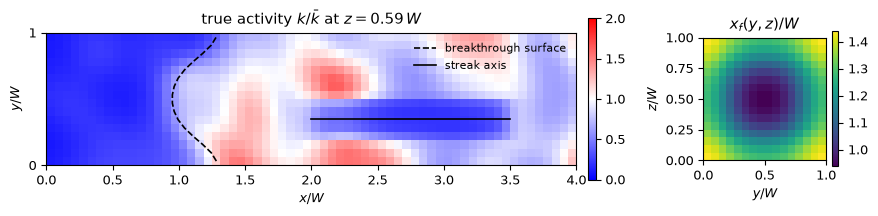

In [15]:
iz = int(np.argmin(np.abs(s_grid - 0.62)))   # the plane through the streak


def axial_plane(ax, values, **kwargs):
    plane = np.asarray(values).reshape(NX, NY, NY)[:, :, iz]
    im = ax.imshow(plane.T, origin="lower", extent=(0, L, 0, W), **kwargs)
    ax.set(ylabel="$y / W$", yticks=[0, 1])
    return im


fig = plt.figure(figsize=(9, 2.6))
ax0 = fig.add_axes([0.06, 0.2, 0.62, 0.62])
ax1 = fig.add_axes([0.79, 0.2, 0.15, 0.62])
im = axial_plane(ax0, k_true / KBAR, cmap="bwr", vmin=0, vmax=2)
ax0.plot(x_f[:, iz], s_grid, "k--", lw=1.2, label="breakthrough surface")
ax0.plot([2.0, 3.5], [0.35, 0.35], "k-", lw=1.2, label="streak axis")
ax0.set(xlabel="$x / W$", title=f"true activity $k / \\bar k$ at $z = {s_grid[iz]:.2f}\\,W$")
ax0.legend(loc="upper right", fontsize=8, frameon=False)
fig.colorbar(im, ax=ax0, fraction=0.03, pad=0.02)
im = ax1.imshow(x_f.T, origin="lower", extent=(0, W, 0, W))
ax1.set(xlabel="$y / W$", ylabel="$z / W$", title="$x_f(y, z) / W$")
fig.colorbar(im, ax=ax1, fraction=0.05, pad=0.04);

We generate the data with a float64 solve at the true activity, saved at the eight measurement times, and add the noise.

In [16]:
sol = ds.pdesolve(problem64, solver64, (0.0, 8.0), y0, theta=ds.default_theta(problem64, {k64: k_true}), saveat=ds.SaveAt(ts=TS))
clean = np.asarray(sol.ys)   # (8, n_cells)
data = clean + SIGMA * np.random.default_rng(7).standard_normal(clean.shape)
print(f"{int(sol.stats.accepts)} steps, {data.size} measurements")

363 steps, 131072 measurements


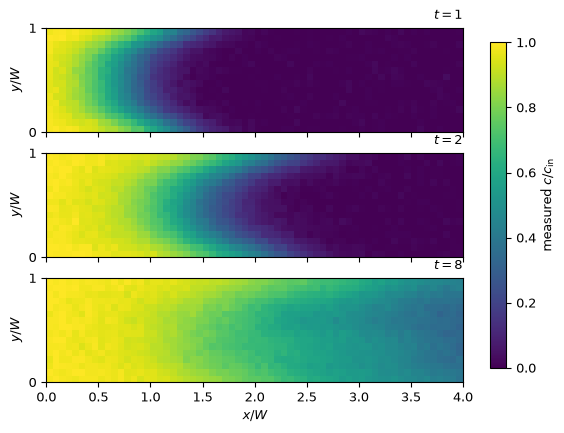

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(7, 4.6), sharex=True)
for ax, n in zip(axes, (0, 1, 7)):
    im = axial_plane(ax, data[n], vmin=0, vmax=1)
    ax.set_title(f"$t = {TS[n]:.0f}$", fontsize=9, loc="right")
axes[-1].set_xlabel("$x / W$")
fig.colorbar(im, ax=axes, label="measured $c / c_{\\mathrm{in}}$", fraction=0.03);

The feed advances fastest along the walls, where the flow channels, and by $t = 8$ the bed is close to steady state.

## The neural field

We parameterize the activity with WIRE (Saragadam et al., CVPR 2023), a coordinate network whose hidden layers apply the real Gabor wavelet

$$
g(z) = \cos(\omega_0 z)\, e^{-(s_0 z)^2},
$$

where $\omega_0$ sets how fast a unit oscillates and $s_0$ how local it is. Its locality lets the network learn a compact feature such as the streak while the field stays smooth elsewhere. `ds.inference.approx.WIRE` builds the network as SIREN, a related network with sine activations, with the Gabor wavelet in place of the sine ([coordinate networks](../overview/inference/function-approximation.md#coordinate-networks)).

`bounds=` maps a cube of side $L$ around the bed onto $[-1, 1]^3$, so that a feature of a given size costs the network the same in every direction. `transform=` turns the raw output into the activity.

In [18]:
def activity(x, raw):
    return KBAR / jnp.log(2.0) * jax.nn.softplus(raw)


cube = ((0.0, L), (W / 2 - L / 2, W / 2 + L / 2), (W / 2 - L / 2, W / 2 + L / 2))
net = ds.inference.approx.WIRE(3, width=WIDTH, depth=DEPTH, omega_0=OMEGA_0, s_0=S_0, bounds=cube,
                               transform=activity, key=jax.random.PRNGKey(0))
x_j = jnp.asarray(x_cells)
n_weights = sum(leaf.size for leaf in jax.tree.leaves(eqx.filter(net, eqx.is_inexact_array)))
print(f"{n_weights} weights, initial k / kbar from {float(net(x_j).min()) / KBAR:.2f} to {float(net(x_j).max()) / KBAR:.2f}")

75073 weights, initial k / kbar from 0.97 to 1.04


We could call the network inside the equation with `spec.function` and `q.fn.<name>(q.x)`, but then it would run at every right-hand side evaluation. Since the activity depends on position alone, we instead evaluate the network once per optimizer step and pass its output as the learnable parameter `k`. The reverse pass of the solve returns the gradient with respect to `k`, and JAX carries it back into the network weights.

## Training

Each optimizer step solves the model from the empty bed to $t = 8$ with JNDF in float32 at $\mathrm{rtol} = 10^{-5}$ and $\mathrm{atol} = 10^{-6}$. The gradient comes from reverse mode with 64 checkpoints ([reverse mode](../overview/simulation/sensitivities.md#reverse-mode-and-checkpointing)).

In [19]:
solver32 = ds.JNDF(rtol=1e-5, atol=1e-6, linear="auto")
adjoint = ds.CheckpointAdjoint(checkpoints=CHECKPOINTS)
data_j = jnp.asarray(data, jnp.float32)


def loss(net):
    sol = ds.pdesolve(problem32, solver32, (0.0, 8.0), y0, theta=ds.default_theta(problem32, {k32: net(x_j)}),
                      saveat=ds.SaveAt(ts=TS), adjoint=adjoint)
    r = (sol.ys - data_j).astype(jnp.float64) / SIGMA
    return 0.5 * jnp.sum(r**2)

Next, we set up AdamW from optax with the gradient clipped to unit norm. The learning rate warms up over the first 5% of the steps and then decays along a cosine to 1% of its peak.

In [20]:
schedule = optax.warmup_cosine_decay_schedule(init_value=PEAK_LR / 10, peak_value=PEAK_LR, warmup_steps=STEPS // 20,
                                              decay_steps=STEPS, end_value=PEAK_LR / 100)
optimizer = optax.chain(optax.clip_by_global_norm(1.0), optax.adamw(schedule, weight_decay=WEIGHT_DECAY))
opt_state = optimizer.init(eqx.filter(net, eqx.is_inexact_array))


@eqx.filter_jit
def step(net, opt_state):
    value, grads = eqx.filter_value_and_grad(loss)(net)
    updates, opt_state = optimizer.update(grads, opt_state, eqx.filter(net, eqx.is_inexact_array))
    return eqx.apply_updates(net, updates), opt_state, value


def rel_l2(k):
    return float(np.linalg.norm(k - k_true) / np.linalg.norm(k_true))

The training loop records the mean squared error in $c$ and the relative $L^2$ error of $k$ at every step. The first step jit compiles the solve and its adjoint, so we time it separately.

In [21]:
history = {"mse": [], "rel_l2": []}
start = time.perf_counter()
for i in range(STEPS):
    history["rel_l2"].append(rel_l2(np.asarray(net(x_j))))   # the field this step's loss sees
    net, opt_state, value = step(net, opt_state)
    history["mse"].append(2 * SIGMA**2 * float(value) / data.size)
    if i == 0:
        compiled = time.perf_counter()
    if i % 100 == 0 or i == STEPS - 1:
        print(f"step {i:4d}   MSE {history['mse'][-1]:.3e}   rel. L2 error of k {history['rel_l2'][-1]:.3f}")
end = time.perf_counter()
print(f"first step {compiled - start:.0f} s, then {(end - compiled) / (STEPS - 1):.2f} s per step")

step    0   MSE 2.265e-02   rel. L2 error of k 0.591


step  100   MSE 2.618e-04   rel. L2 error of k 0.196


step  200   MSE 1.641e-04   rel. L2 error of k 0.134


step  300   MSE 1.136e-04   rel. L2 error of k 0.108


step  400   MSE 1.067e-04   rel. L2 error of k 0.086


...

step  800   MSE 1.002e-04   rel. L2 error of k 0.051


step  900   MSE 9.976e-05   rel. L2 error of k 0.048


step 1000   MSE 9.957e-05   rel. L2 error of k 0.046


step 1100   MSE 9.948e-05   rel. L2 error of k 0.046


step 1199   MSE 9.943e-05   rel. L2 error of k 0.045
first step 13 s, then 1.24 s per step


## Results

A final float32 solve with the learned field gives the misfit to compare with the noise floor.

In [22]:
k_fit = np.asarray(net(x_j))
sol_fit = ds.pdesolve(problem32, solver32, (0.0, 8.0), y0, theta=ds.default_theta(problem32, {k32: k_fit}), saveat=ds.SaveAt(ts=TS))
mse = float(np.mean((np.asarray(sol_fit.ys) - data) ** 2))
print(f"MSE {mse:.3e}, noise floor sigma^2 = {SIGMA**2:.0e}")
print(f"relative L2 error of k: {rel_l2(k_fit):.3f}")

MSE 9.943e-05, noise floor sigma^2 = 1e-04
relative L2 error of k: 0.045


The misfit of $9.94 \times 10^{-5}$ sits at the noise floor $\sigma^2 = 10^{-4}$, and the relative $L^2$ error of $k$ is 0.045. To compare the front and the streak with the truth, we divide an activity by $\bar k e^{\psi}$, which removes the random factor. The breakthrough surface is then where each axial column of this ratio first passes 0.6, halfway up the front.

In [23]:
def breakthrough(k):
    ratio = (k / (KBAR * np.exp(psi))).reshape(NX, NY, NY)
    above = ratio >= 0.6
    i = np.clip(np.argmax(above, axis=0), 1, NX - 1)   # first cell past the midpoint
    lo = np.take_along_axis(ratio, i[None] - 1, 0)[0]
    hi = np.take_along_axis(ratio, i[None], 0)[0]
    x_cross = s_x[i - 1] + (0.6 - lo) / (hi - lo) * (s_x[i] - s_x[i - 1])
    return np.where(above.any(axis=0), x_cross, np.nan)


ix = int(np.argmin(np.abs(s_x - 2.75)))   # a cut across the middle of the streak


def streak_profile(k):
    return (k / (KBAR * np.exp(psi))).reshape(NX, NY, NY)[ix, :, iz]

In [24]:
x_f_fit = breakthrough(k_fit)
print(f"RMS error of the breakthrough surface: {np.sqrt(np.nanmean((x_f_fit - x_f) ** 2)):.3f} W "
      f"(from {np.sqrt(np.nanmean((breakthrough(k_true) - x_f) ** 2)):.3f} W on the truth)")
print(f"activity at the streak's centre: learned {streak_profile(k_fit).min():.2f}, "
      f"true {streak_profile(k_true).min():.2f}")

RMS error of the breakthrough surface: 0.015 W (from 0.000 W on the truth)
activity at the streak's centre: learned 0.28, true 0.30


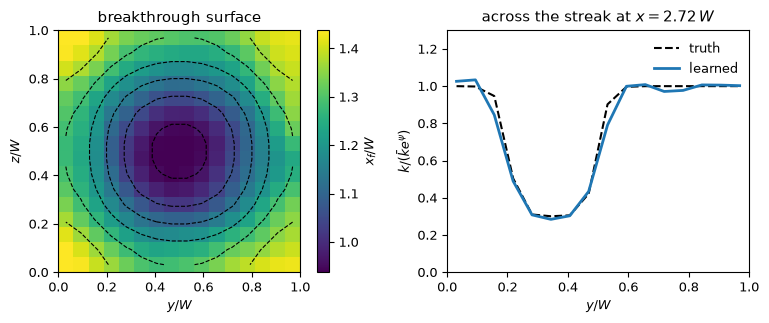

In [25]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(8, 3.3), width_ratios=[1.1, 1])
im = ax0.imshow(x_f_fit.T, origin="lower", extent=(0, W, 0, W), vmin=x_f.min(), vmax=x_f.max())
ax0.contour(s_grid, s_grid, x_f.T, levels=6, colors="k", linestyles="--", linewidths=0.8)
fig.colorbar(im, ax=ax0, label="$x_f / W$")
ax0.set(xlabel="$y / W$", ylabel="$z / W$", title="breakthrough surface")
ax1.plot(s_grid, streak_profile(k_true), "k--", label="truth")
ax1.plot(s_grid, streak_profile(k_fit), color="tab:blue", lw=2, label="learned")
ax1.set(xlabel="$y / W$", ylabel="$k / (\\bar k e^{\\psi})$", xlim=(0, 1), ylim=(0, 1.3),
        title=f"across the streak at $x = {s_x[ix]:.2f}\\,W$")
ax1.legend(frameon=False)
fig.tight_layout()

The learned breakthrough surface follows the true contours, deepest in the wall channel and shallowest at the centre, with an RMS error of $0.015\,W$. Across the streak, the learned dip reaches 0.28 against the true 0.30 and matches its width to within a cell.

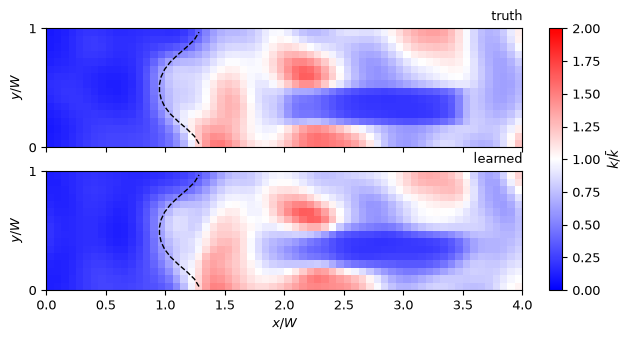

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(7, 3.4), sharex=True)
for ax, k, name in zip(axes, (k_true, k_fit), ("truth", "learned")):
    im = axial_plane(ax, k / KBAR, cmap="bwr", vmin=0, vmax=2)
    ax.plot(x_f[:, iz], s_grid, "k--", lw=1)
    ax.set_title(name, fontsize=9, loc="right")
axes[-1].set_xlabel("$x / W$")
fig.colorbar(im, ax=axes, label="$k / \\bar k$", fraction=0.03);

The learned field reproduces the front, the streak and the large patches of the random factor. It smooths the finest texture, since dispersion has already blurred it out of the measured concentration.

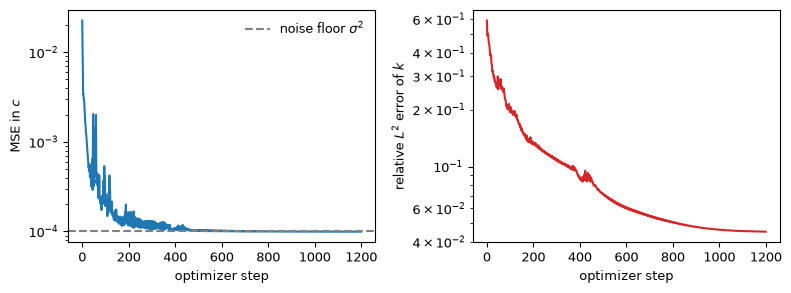

In [27]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(8, 3))
ax0.semilogy(history["mse"], color="tab:blue")
ax0.axhline(SIGMA**2, color="0.5", ls="--", label="noise floor $\\sigma^2$")
ax0.set(xlabel="optimizer step", ylabel="MSE in $c$")
ax0.legend(frameon=False)
ax1.semilogy(history["rel_l2"], color="tab:red")
ax1.set(xlabel="optimizer step", ylabel="relative $L^2$ error of $k$")
fig.tight_layout()

The misfit reaches the noise floor within a few hundred steps, while the error in $k$ keeps falling until the learning rate has decayed.

## Comparison with the paper

The paper trained on the 96 × 24 × 24 grid for 1200 steps and reached a relative $L^2$ error in $k$ of about 0.045. This run reaches the same error on a coarser grid, but our random field is a different draw, so the two numbers are not directly comparable.


To reproduce the paper's run, set the right-hand values in the configuration cell.